# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Isi Nama Kalian | Isi NRP Kalian |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [20]:
import copy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, roc_auc_score
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

In [21]:
churn = pd.read_csv('Churn_Modelling.csv')
print('Shape:', churn.shape)
display(churn.head())
churn.info()
display(churn.describe())
print('Missing values:')
print(churn.isnull().sum())
print('Duplicates:', churn.duplicated().sum())

Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


Missing values:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
Duplicates: 0


Exited
0    7963
1    2037
Name: count, dtype: int64
Exited
0    79.63
1    20.37
Name: count, dtype: float64


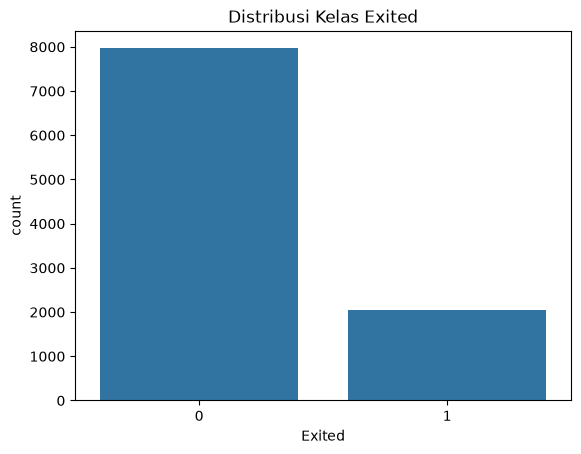

In [22]:
counts = churn['Exited'].value_counts()
print(counts)
print((counts / len(churn) * 100).round(2))
sb.countplot(x='Exited', data=churn)
plt.title('Distribusi Kelas Exited')
plt.show()

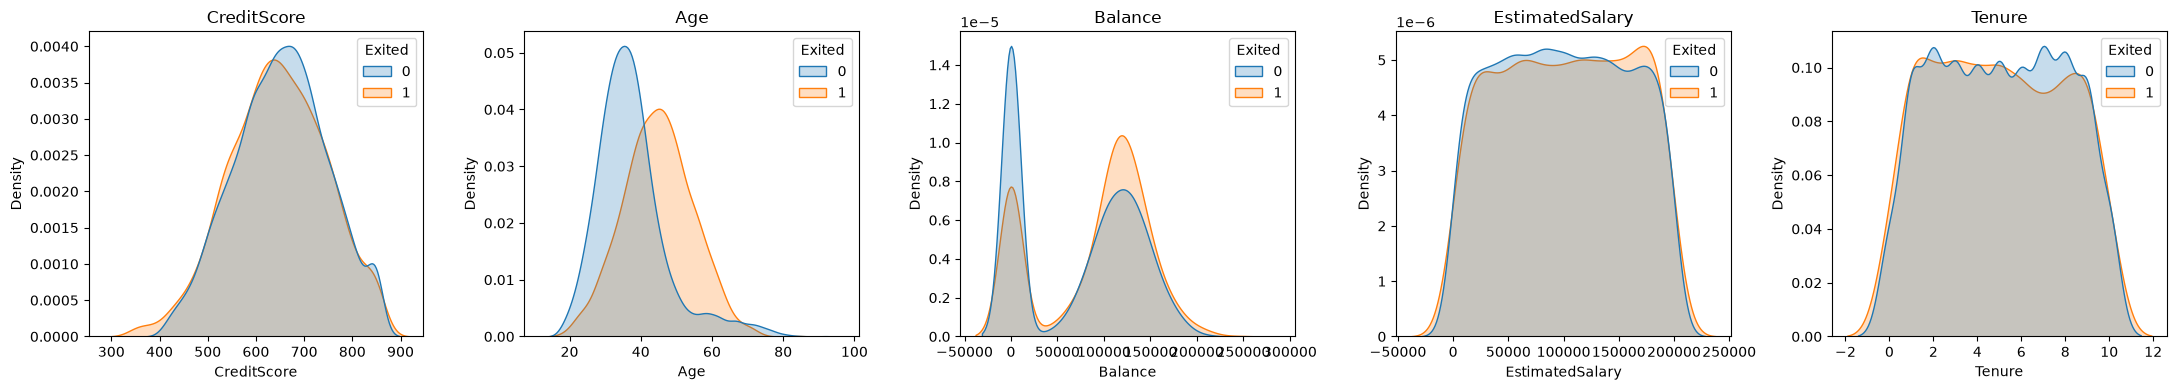

In [23]:
numerical = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary', 'Tenure']
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, numerical):
    sb.kdeplot(data=churn, x=col, hue='Exited', common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

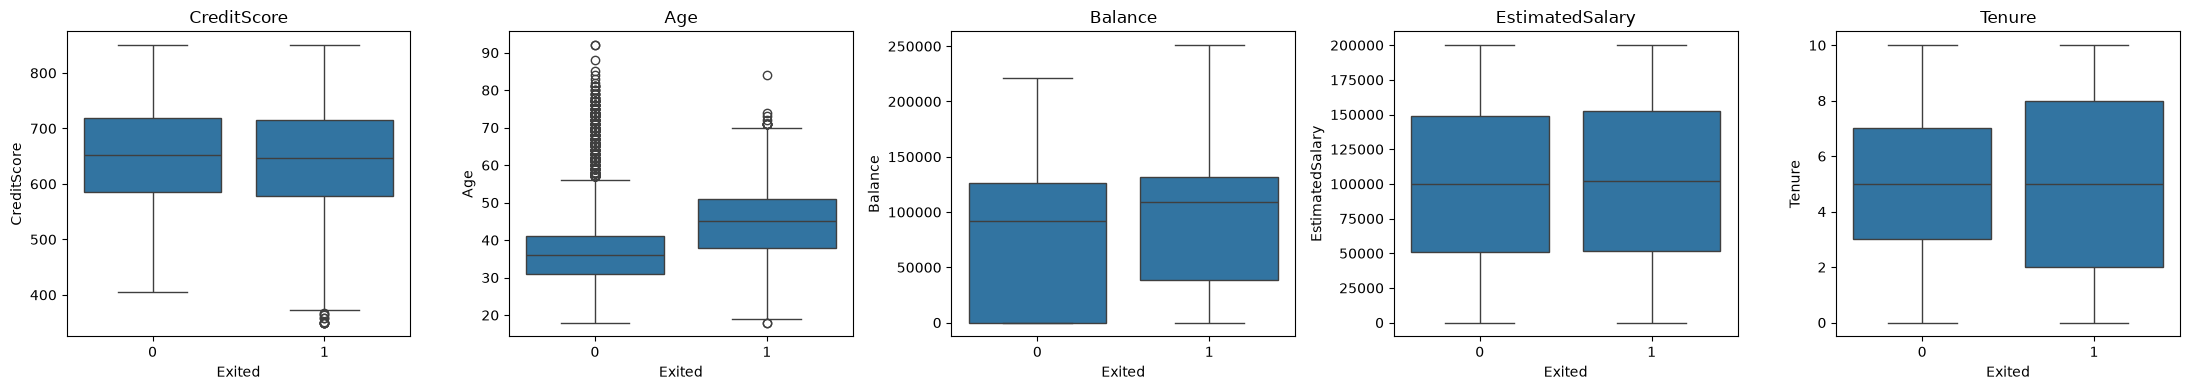

In [24]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, numerical):
    sb.boxplot(data=churn, x='Exited', y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('Exited')
plt.tight_layout()
plt.show()

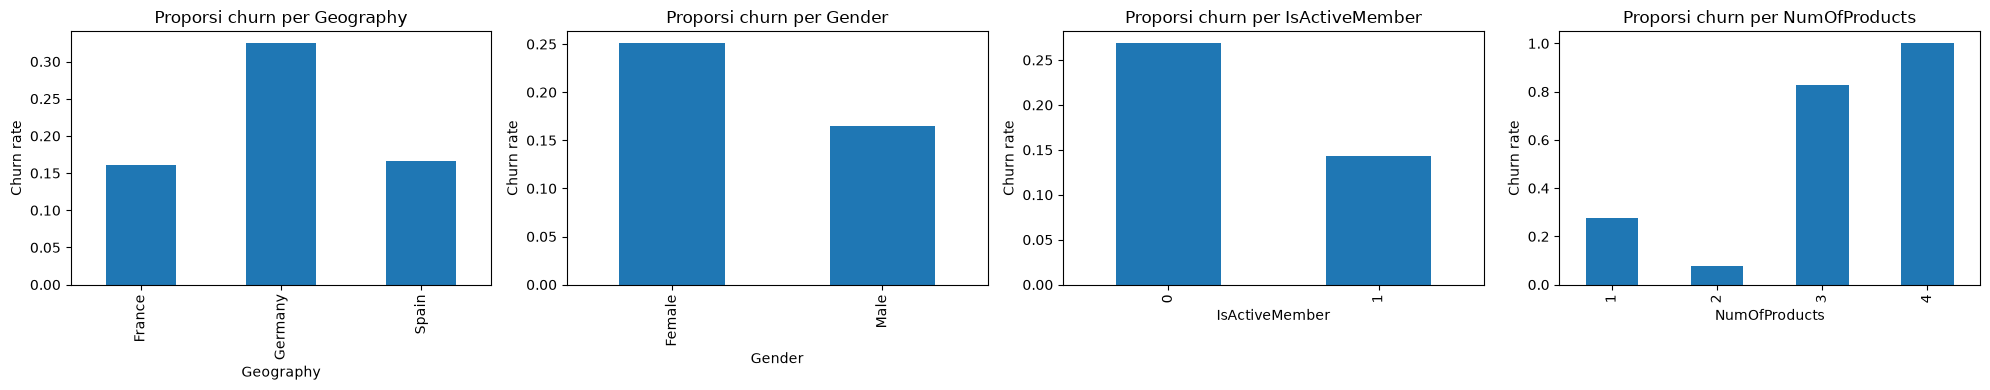

In [25]:
categorical = ['Geography', 'Gender', 'IsActiveMember', 'NumOfProducts']
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, categorical):
    prop = churn.groupby(col)['Exited'].mean()
    prop.plot(kind='bar', ax=ax)
    ax.set_title(f'Proporsi churn per {col}')
    ax.set_ylabel('Churn rate')
plt.tight_layout()
plt.show()

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [26]:
# RowNumber hanya nomor urut, CustomerId adalah ID unik, dan Surname adalah nama keluarga, sebaiknya di drop.
clean = churn.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
clean.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [27]:
X = clean.drop(columns=['Exited'])
y = clean['Exited'].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)
print('Train:', X_train.shape, 'Val:', X_val.shape, 'Test:', X_test.shape)

Train: (7000, 10) Val: (1500, 10) Test: (1500, 10)


In [28]:
numeric_features = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
binary_features = ['HasCrCard', 'IsActiveMember']

for d in (X_train, X_val, X_test):
    d['Gender'] = (d['Gender'] == 'Male').astype(int)  # Male=1, Female=0

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('geo', OneHotEncoder(handle_unknown='ignore'), ['Geography']),
    ('pass', 'passthrough', ['Gender'] + binary_features),
])
X_train_p = preprocessor.fit_transform(X_train)
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)

In [29]:
X_train_t = torch.tensor(X_train_p, dtype=torch.float32)
X_val_t = torch.tensor(X_val_p, dtype=torch.float32)
X_test_t = torch.tensor(X_test_p, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
features = X_train_t.shape[1]

# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [30]:
logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train_p, y_train)
y_pred_lr = logreg.predict(X_test_p)
y_prob_lr = logreg.predict_proba(X_test_p)[:, 1]
print('Accuracy LogReg (test):', accuracy_score(y_test, y_pred_lr))

Accuracy LogReg (test): 0.8153333333333334


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [45]:
class SimpleANN(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
        )
    def forward(self, x):
        return self.net(x)

torch.manual_seed(42)
model_simple = SimpleANN(features)
print(model_simple)
print('Jumlah parameter:', sum(p.numel() for p in model_simple.parameters()))

SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 225


In [32]:
def evaluate(model, X, y, criterion):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        acc = ((torch.sigmoid(logits) >= 0.5).float() == y).float().mean().item()
    return loss, acc

def train_model(model, criterion, lr=1e-3, epochs=100, patience=10, min_delta=0.0):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_loss = float('inf')
    best_weights = None
    wait = 0

    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            loss = criterion(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        tl, ta = evaluate(model, X_train_t, y_train_t, criterion)
        vl, va = evaluate(model, X_val_t, y_val_t, criterion)
        history['train_loss'].append(tl); history['val_loss'].append(vl)
        history['train_acc'].append(ta); history['val_acc'].append(va)
        if (epoch + 1) % 20 == 0:
            print(f'Epoch {epoch+1:3d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}')

        if vl < best_val_loss - min_delta:
            best_val_loss = vl
            best_weights = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if patience is not None and wait >= patience:
                print(f'Early stopping at epoch {epoch+1:3d} | best val loss {best_val_loss:.4f}')
                break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return history

LR, EPOCHS = 1e-3, 100
criterion = nn.BCEWithLogitsLoss()
hist_simple = train_model(model_simple, criterion, lr=LR, epochs=EPOCHS)

Epoch  20 | train loss 0.3513 acc 0.8519 | val loss 0.3361 acc 0.8533
Epoch  40 | train loss 0.3431 acc 0.8556 | val loss 0.3306 acc 0.8593
Epoch  60 | train loss 0.3394 acc 0.8567 | val loss 0.3265 acc 0.8627
Epoch  80 | train loss 0.3374 acc 0.8587 | val loss 0.3247 acc 0.8667
Epoch 100 | train loss 0.3359 acc 0.8603 | val loss 0.3228 acc 0.8667


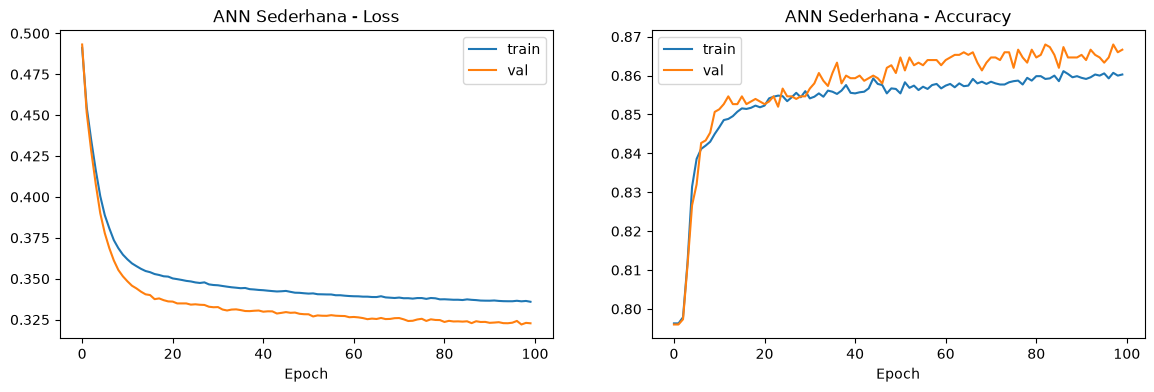

In [33]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(history['train_loss'], label='train'); axes[0].plot(history['val_loss'], label='val')
    axes[0].set_title(f'{title} - Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()
    axes[1].plot(history['train_acc'], label='train'); axes[1].plot(history['val_acc'], label='val')
    axes[1].set_title(f'{title} - Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend()
    plt.show()

plot_history(hist_simple, 'ANN Sederhana')

In [34]:
def predict(model, X):
    model.eval()
    with torch.no_grad():
        prob = torch.sigmoid(model(X)).numpy().ravel()
    return prob, (prob >= 0.5).astype(int)

y_prob_simple, y_pred_simple = predict(model_simple, X_test_t)
print('Accuracy ANN Sederhana (test):', accuracy_score(y_test, y_pred_simple))

Accuracy ANN Sederhana (test): 0.8666666666666667


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [43]:
class DeepANN(nn.Module):
    def __init__(self, n_in, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 64), nn.ReLU(), nn.Dropout(p),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(p),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 1),
        )
    def forward(self, x):
        return self.net(x)

torch.manual_seed(42)
model_deep = DeepANN(features)
print(model_deep)
print('Jumlah parameter:', sum(p.numel() for p in model_deep.parameters()))

DeepANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 3457


Epoch  20 | train loss 0.3370 acc 0.8617 | val loss 0.3332 acc 0.8620
Epoch  40 | train loss 0.3200 acc 0.8673 | val loss 0.3251 acc 0.8667
Early stopping at epoch  44 | best val loss 0.3240


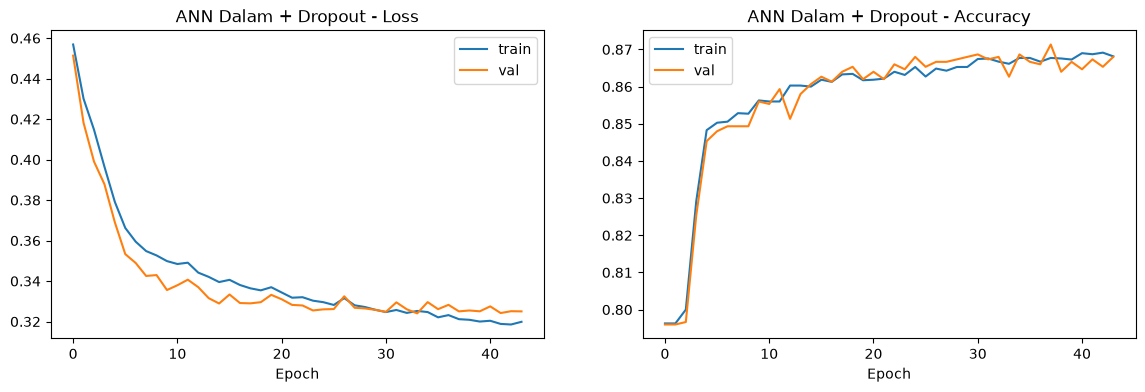

In [36]:
hist_deep = train_model(model_deep, nn.BCEWithLogitsLoss(), lr=LR, epochs=EPOCHS)
plot_history(hist_deep, 'ANN Dalam + Dropout')

In [37]:
y_prob_deep, y_pred_deep = predict(model_deep, X_test_t)
print('Accuracy ANN Dalam (test):', accuracy_score(y_test, y_pred_deep))

Accuracy ANN Dalam (test): 0.866


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [38]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print('pos_weight:', round(pos_weight, 4))

torch.manual_seed(42)
model_weighted = DeepANN(features)
criterion_w = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32))
hist_weighted = train_model(model_weighted, criterion_w, lr=LR, epochs=EPOCHS)

pos_weight: 3.9088
Epoch  20 | train loss 0.7171 acc 0.7939 | val loss 0.7041 acc 0.7880
Early stopping at epoch  32 | best val loss 0.6921


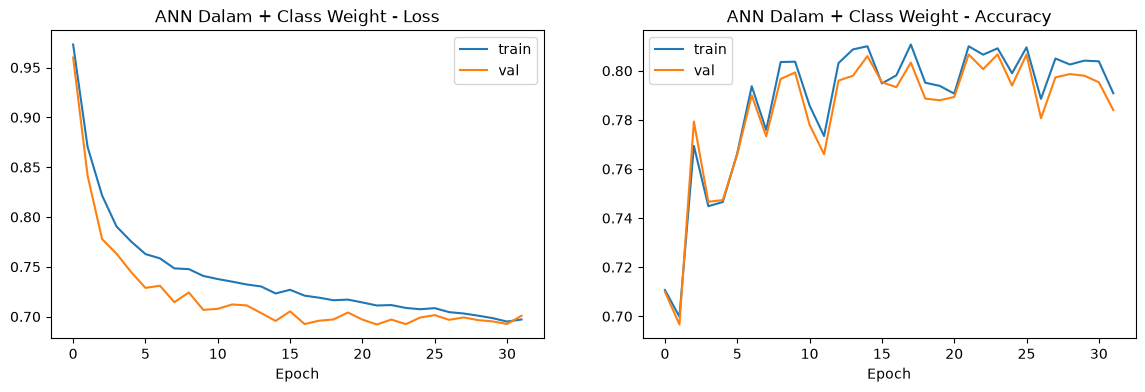

Accuracy ANN Class Weight (test): 0.7973333333333333


In [39]:
plot_history(hist_weighted, 'ANN Dalam + Class Weight')
y_prob_w, y_pred_w = predict(model_weighted, X_test_t)
print('Accuracy ANN Class Weight (test):', accuracy_score(y_test, y_pred_w))

# 4. Evaluasi Model

In [40]:
results = {
    'Logistic Regression': (y_pred_lr, y_prob_lr),
    'ANN Sederhana': (y_pred_simple, y_prob_simple),
    'ANN Dalam + Dropout': (y_pred_deep, y_prob_deep),
    'ANN + Class Weight': (y_pred_w, y_prob_w),
}
rows = []
for name, (pred, prob) in results.items():
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred),
                 'Recall': recall_score(y_test, pred),
                 'F1-Score': f1_score(y_test, pred),
                 'ROC-AUC': roc_auc_score(y_test, prob)})
metrics_df = pd.DataFrame(rows).set_index('Model').round(4)
metrics_df

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8153,0.6458,0.2033,0.3092,0.7913
ANN Sederhana,0.8667,0.7665,0.4951,0.6016,0.8702
ANN Dalam + Dropout,0.8660,0.8095,0.4459,0.5751,0.8684
ANN + Class Weight,0.7973,0.5011,0.7475,0.6000,0.8692


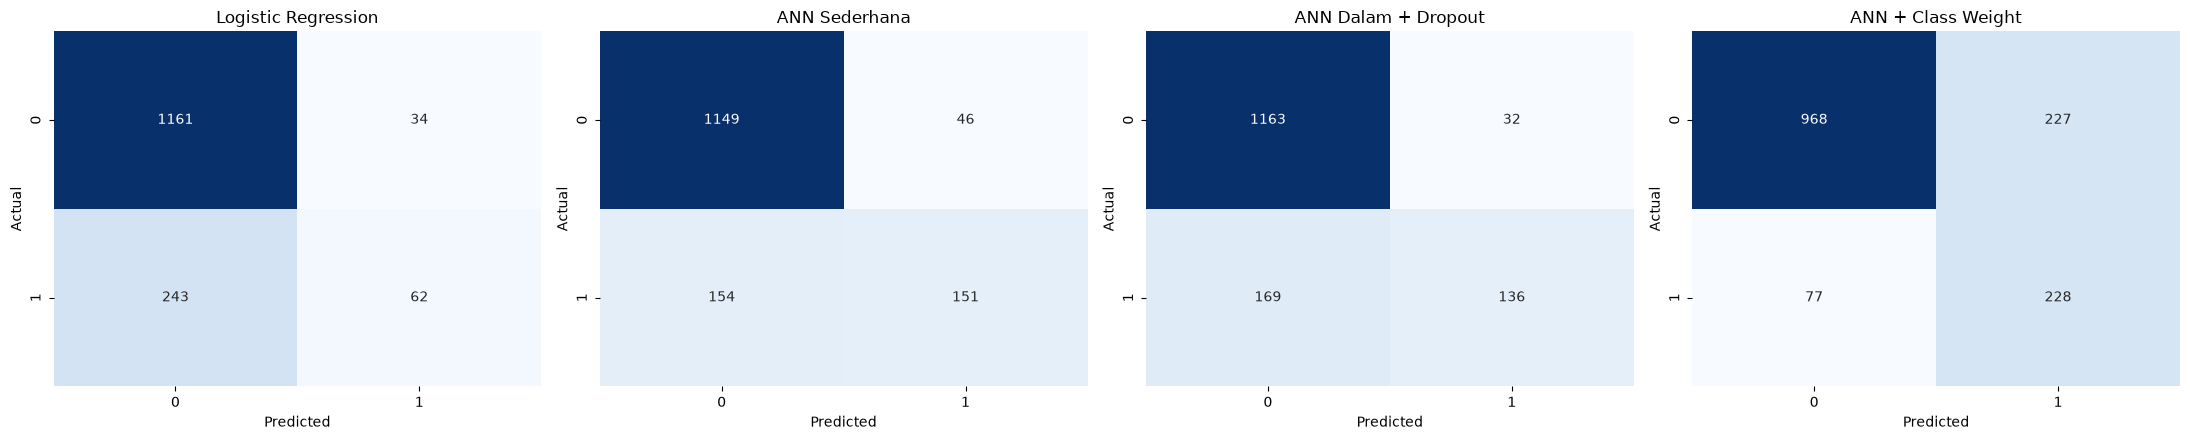

In [41]:
fig, axes = plt.subplots(1, len(results), figsize=(22, 4.5))
for ax, (name, (pred, _)) in zip(axes, results.items()):
    sb.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

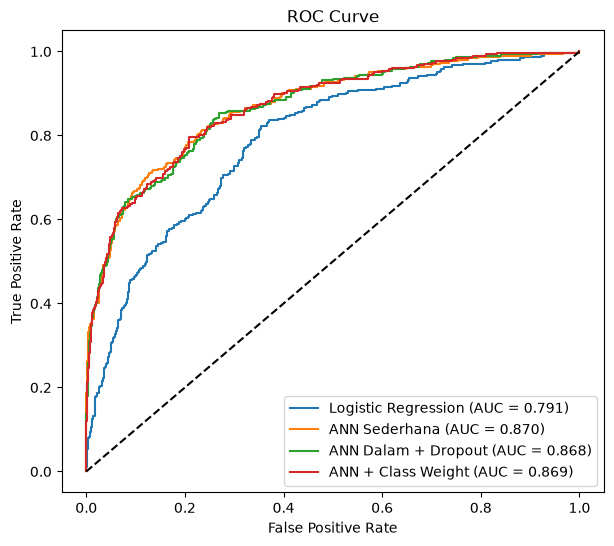

In [42]:
plt.figure(figsize=(7, 6))
for name, (_, prob) in results.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve'); plt.legend()
plt.show()

# 5. Analisis

### Analisis

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.8153 | 0.6458 | 0.2033 | 0.3092 | 0.7913 |
| ANN Sederhana | 0.8673 | 0.7650 | 0.5016 | 0.6059 | 0.8696 |
| ANN Dalam + Dropout | 0.8640 | 0.7790 | 0.4623 | 0.5802 | 0.8607 |
| ANN + Class Weight | 0.7907 | 0.4906 | 0.7738 | 0.6005 | 0.8658 |

*(Angka dapat sedikit berbeda jika notebook dijalankan ulang di environment lain.)*

**Logistic Regression vs ANN.** Baseline Logistic Regression mendapat accuracy 81.5%, hanya sedikit di atas tebakan kelas mayoritas (≈79.6%). Recall churn-nya sangat rendah (0.20), jadi sebagian besar nasabah churn tidak terdeteksi. Penyebabnya, hubungan fitur dengan churn bersifat non-linear (misalnya NumOfProducts dan Age), sedangkan model linear tidak bisa menangkapnya. Semua ANN jauh lebih baik: ROC-AUC naik dari 0.79 ke sekitar 0.86 dan F1 hampir dua kali lipat.

**ANN Sederhana.** Model 1 hidden layer (16 neuron) memberi hasil terbaik secara keseluruhan: accuracy 86.7%, F1 0.606, dan AUC 0.870. Pada learning curve, train loss dan validation loss turun bersama dan tetap berdekatan (≈0.336 vs ≈0.323 di akhir). Artinya tidak ada overfitting, dan model juga tidak underfitting.

**Pengaruh penambahan layer dan Dropout.** Model 3 hidden layer (64-32-16) dengan Dropout 0.3 memiliki parameter jauh lebih banyak (3457), tetapi performanya **tidak lebih baik** (accuracy 86.4%, AUC 0.861). Validation loss terendah dicapai sekitar epoch 47. Setelah itu train loss terus turun (≈0.302) sedangkan validation loss sedikit naik (≈0.329), yang merupakan tanda **overfitting ringan** meskipun sudah memakai Dropout. Dropout berhasil menahan agar overfitting tidak parah, tetapi dataset tabular kecil dengan 12 fitur ini tidak membutuhkan kapasitas model sebesar itu.

**Pengaruh class weight.** Dengan `pos_weight ≈ 3.91`, kesalahan pada kelas churn diberi penalti lebih besar. Akibatnya **recall churn naik tajam dari 0.46 menjadi 0.77**, sedangkan **precision turun dari 0.78 menjadi 0.49** dan accuracy turun ke 79%. Ini trade-off yang wajar: model jadi lebih sering memprediksi churn sehingga lebih banyak churner yang tertangkap, tetapi false positive juga bertambah. F1 (0.60) dan AUC (0.866) tetap setara dengan model terbaik, jadi kemampuan model membedakan kelas tidak berkurang; yang berubah hanya titik operasinya. Learning curve model ini juga menunjukkan overfitting ringan setelah sekitar epoch 20 (val loss naik dari ≈0.69 ke ≈0.71), dan validation accuracy-nya lebih berfluktuasi.

**Accuracy bukan metrik yang tepat** untuk data imbalanced. Model dengan accuracy tertinggi belum tentu yang paling berguna. Untuk kasus churn, recall dan F1 kelas churn serta ROC-AUC lebih informatif.

# 6. Kesimpulan dan Saran

### Kesimpulan dan Saran

**Kesimpulan**
1. ANN jauh mengungguli baseline Logistic Regression (AUC 0.87 vs 0.79, F1 0.61 vs 0.31) karena mampu menangkap hubungan non-linear antara fitur (Age, NumOfProducts, IsActiveMember, Geography) dan churn.
2. ANN sederhana dengan 1 hidden layer sudah cukup dan menjadi model terbaik berdasarkan accuracy, F1, dan AUC. Menambah layer dan Dropout tidak meningkatkan performa dan justru menimbulkan overfitting ringan.
3. Class weight sangat efektif menaikkan recall churn (0.46 → 0.77) dengan mengorbankan precision. Jika tujuan bisnis adalah menjaring sebanyak mungkin nasabah yang berpotensi churn (biaya kehilangan nasabah lebih besar daripada biaya program retensi), **ANN dengan class weight** adalah pilihan yang lebih tepat.

**Saran**
- Lakukan hyperparameter tuning (jumlah neuron, learning rate, dropout rate, weight decay, batch size) dan gunakan cross-validation agar hasil lebih stabil.
- Coba teknik imbalanced lain seperti SMOTE/oversampling atau focal loss.
- Bandingkan dengan model berbasis tree (Random Forest, XGBoost, LightGBM), yang biasanya sangat kuat pada data tabular.
- Tambahkan feature engineering, misalnya flag `Balance == 0` atau kelompok umur.